In [1]:
# source ~/load_modules_pitts_spack-26.1.sh
# module unload --no-auto py-typing-extensions py-pylint-gitlab -f
# module load py-pip
# DISPLAY= PYTHONPATH=$PYTHONPATH:~/pitts_clean/examples/.python-packages/lib/python3.14/site-packages/:~/pitts_clean/build/src/ .python-packages/bin/jupyter notebook
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource
import pitts_py
from IPython import display
import scipy.spatial
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['savefig.transparent'] = False
#plt.rcParams['agg.transparent'] = False

In [2]:
def saveVideo(name, data):
    file_name = "Interactive_DeepArc_examples_" + name + ".mp4"
    fourcc = cv2.VideoWriter_fourcc(*'vp09')
    n_frames = data.shape[0]
    width = data.shape[1]
    height = data.shape[2]
    out = cv2.VideoWriter(file_name, cv2.CAP_FFMPEG, fourcc, 30, (height, width), 1)
    normalized_data = data / np.max(data)
    normalized_data = np.maximum(0, normalized_data)
    cmap = plt.get_cmap('viridis')
    img_data = cmap(normalized_data, bytes=True)
    for i in range(n_frames):
        out.write(cv2.cvtColor(img_data[i,...], cv2.COLOR_RGBA2BGR))
    out.release()
    return file_name

In [3]:
def compareVideo(name, data_list):
    all_data = np.concatenate(data_list, axis=2)
    return saveVideo(name, all_data)

In [4]:
def dict_to_tensortrain(tt_dict):
    Xtt = pitts_py.TensorTrain_float(tt_dict['dimensions'])
    Xtt.setTTranks(tt_dict['ranks'])
    for i in range(len(Xtt.dimensions())):
        Xtt.setSubTensor(i, tt_dict['cores'][i])
    return Xtt

In [5]:
X = np.load('/scratch/DeepArk_mirror/SANS_CM/stackedPixelData.npy', mmap_mode='r')
# (patient, slice, time, x, y)
X.shape

(19, 19, 300, 200, 200)

In [6]:
maxVal = np.max(X)
maxVal

np.uint16(4095)

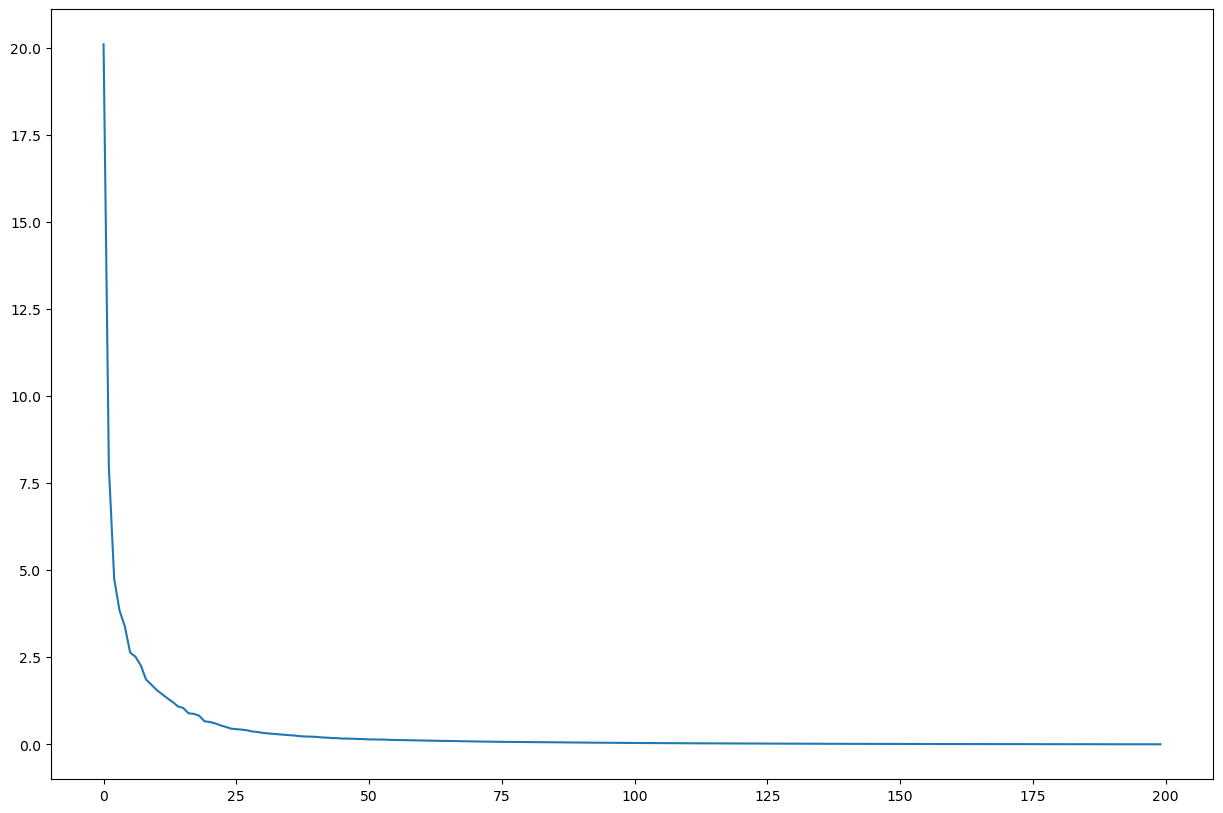

In [7]:
# Example for 2d SVD
frame = X[0,0,0,:,:] / maxVal
U, S, Vt = np.linalg.svd(frame, full_matrices=False)
plt.plot(S)

In [8]:
fig, ax = plt.subplots(tight_layout=True)
ax.axis('off');
ax.title.set_size(30)
def animate(i):
    r = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 50, 100, 200][i]
    ax.imshow((U[:,:r] @ np.diag(S[:r]) @ Vt[:r,:]))
    if r == 200:
        ax.title.set_text('original')
    else:
        ax.title.set_text('rank %d approximation'%(r))
anim = FuncAnimation(fig, animate, frames=15, interval=500)
svd_video = "Interactive_DeepArc_examples_svd_example.mp4" 
anim.save(svd_video, dpi=300, codec='vp9')
plt.close()

In [9]:
display.Video(svd_video)

In [10]:
# example for SVD over time
movie = X[0,0,:,:,:] / maxVal
time_x_img = movie.reshape((300,200*200))
U, S, Vt = np.linalg.svd(time_x_img, full_matrices=False)
movie_r3 = np.reshape(U[:,:3] @ np.diag(S[:3]) @ Vt[:3,:], movie.shape)
movie_r10 = np.reshape(U[:,:10] @ np.diag(S[:10]) @ Vt[:10,:], movie.shape)

In [11]:
display.Video(compareVideo('svd_over_time', (movie_r3, movie_r10, movie)))

In [12]:
pitts_py.initialize()

In [13]:
# TT-SVD movie
def copy_to_multivector(X, dims):
    n_total = np.prod(dims)
    mvX = pitts_py.MultiVector_float(n_total//dims[-1], dims[-1])
    mvX_view = np.array(mvX, copy=False)
    mvX_view[...] = X.reshape(mvX_view.shape, order='F')
    return mvX

dims = (200,200,300)
mvX = copy_to_multivector(movie.T, dims)
mvWork = pitts_py.MultiVector_float()
ttX = pitts_py.fromDense_twoSided(mvX, mvWork, dims, rankTolerance=0, maxRank=10)

PITTS: version v0.9.7-160-ga0937f3-dirty
PITTS: MPI #procs: 1
PITTS: OpenMP #threads: 48
PITTS: SIMD implementation: avx512
PITTS: Eigen SIMD implementation: AVX512, FMA, AVX2, AVX, SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2
PITTS: cache sizes (L1/core, L2/core, L3/accessible) [byte]: (49152, 1310720, 37748736)
PITTS: preprocessor definitions: PITTS_DIRECT_MKL_GEMM
HOSVD::split  matrix dimensions: 40000 x 300
singular values:  366.168  57.1449  24.3955  16.7859   12.447  10.9294  9.82197  8.40666  7.19338  6.89883  6.24464  5.51697  5.38569  5.22931  5.01623  4.84271  4.77579  4.67488  4.33568  4.23605   4.1388  3.97116  3.94288  3.76989  3.69339  3.65706  3.55013  3.49651  3.34633  3.28626  3.25378  3.21694  3.05302  3.02502  2.90138  2.84133  2.78033  2.77963  2.69051  2.63109  2.59631  2.50429  2.47039  2.43324   2.3543  2.33045  2.31119  2.27212   2.2344  2.19358  2.14252  2.11807  2.08721  1.98542  1.97664  1.96654  1.91148  1.87029  1.83902  1.82006  1.77156  1.72231  1.70735  1.6479

In [14]:
print(ttX)

PITTS::TensorTrainfloat
        with dimensions = [200, 200, 300]
             ranks      = [10, 10]


In [15]:
movie_tt10 = pitts_py.toDense(ttX)
movie_tt10.shape

(200, 200, 300)

In [16]:
mvX = copy_to_multivector(movie.T, dims)
mvWork = pitts_py.MultiVector_float()
ttX = pitts_py.fromDense_twoSided(mvX, mvWork, dims, rankTolerance=0, maxRank=25)

95     1.81619     1.79016     1.71907     1.70647     1.69608     1.64872     1.60779     1.56451      1.5474     1.49661     1.48708     1.43173     1.39781     1.38979     1.37936     1.34243     1.32075     1.30796     1.27987     1.26904     1.25377     1.23711     1.21077     1.19982     1.17907     1.16601     1.13427     1.10431     1.08913     1.07675     1.07475     1.04641     1.03739     1.00977    0.999531    0.980151     0.96592    0.958994    0.944008    0.925347    0.905655     0.88196    0.860092     0.85333    0.850953    0.835348    0.828857    0.798561    0.787521    0.778984    0.761234    0.757092    0.740307    0.738937    0.726908    0.707129    0.700624    0.694263    0.690313    0.664935    0.657095    0.643463    0.628832    0.625765    0.610423     0.59621      0.5896     0.57212    0.567723     0.56484    0.552346    0.540164     0.53012    0.528307    0.515444    0.496259    0.493079    0.480331    0.472697    0.465122    0.460742    0.452277    0.444598  

In [17]:
print(ttX)

PITTS::TensorTrainfloat
        with dimensions = [200, 200, 300]
             ranks      = [25, 25]


In [18]:
movie_tt25 = pitts_py.toDense(ttX)
movie_tt25.shape

(200, 200, 300)

In [19]:
display.Video(compareVideo('tt_movie_example', (movie_tt10.T, movie_tt25.T, movie)))

In [20]:
movie.size

12000000

In [21]:
ttSize = ttX.getSubTensor(0).size + ttX.getSubTensor(1).size + ttX.getSubTensor(2).size
movie.size / ttSize

87.27272727272727

In [22]:
# SLICES
sliceFrames = X[0,:,0,:,:] / maxVal
fig, ax = plt.subplots(tight_layout=True)
ax.axis('off')
def animate(i):
    ax.imshow(sliceFrames[i,:,:])
anim = FuncAnimation(fig, animate, frames=19, interval=500)
slices_visu = "Interactive_DeepArc_examples_slices_example.mp4"
anim.save(slices_visu, codec='vp9')
plt.close()

In [23]:
display.Video(slices_visu)

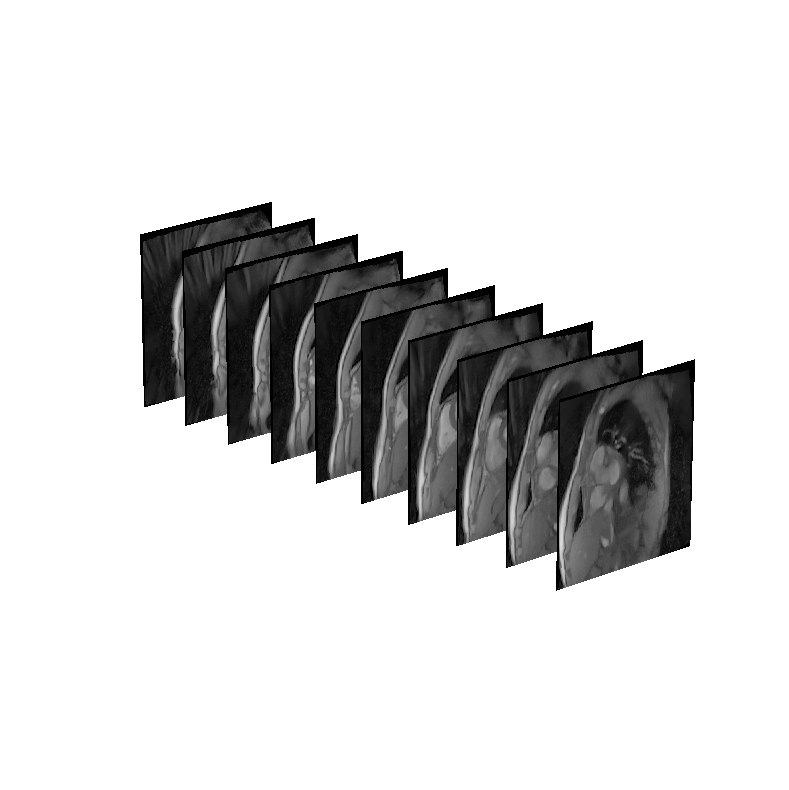

In [65]:
sliceFrames = X[0,:,0,:,:] / maxVal
_X = np.arange(200)
_Y = np.arange(200)
_X, _Y = np.meshgrid(_X, _Y)
_Z = np.zeros((200,200))
cmap = plt.get_cmap('Greys_r')

#%matplotlib notebook
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.axis('off')
ls = LightSource(azdeg=-150)
#sliceFrames = np.rot90(sliceFrames, axes=(2, 1))
ax.plot_surface(_Y, _Z+0, -_X, facecolors=cmap(np.sqrt(sliceFrames[0,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+1, -_X, facecolors=cmap(np.sqrt(sliceFrames[2,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+2, -_X, facecolors=cmap(np.sqrt(sliceFrames[4,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+3, -_X, facecolors=cmap(np.sqrt(sliceFrames[6,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+4, -_X, facecolors=cmap(np.sqrt(sliceFrames[8,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+5, -_X, facecolors=cmap(np.sqrt(sliceFrames[10,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+6, -_X, facecolors=cmap(np.sqrt(sliceFrames[12,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+7, -_X, facecolors=cmap(np.sqrt(sliceFrames[14,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+8, -_X, facecolors=cmap(np.sqrt(sliceFrames[16,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.plot_surface(_Y, _Z+9, -_X, facecolors=cmap(np.sqrt(sliceFrames[18,:,:].T)), linewidth=0, antialiased=False, rcount=200, ccount=200, shade=True, lightsource=ls)
ax.view_init(elev=20, azim=-130)
ax.set_box_aspect((4,15,4))
plt.savefig('slices_gallery.png', dpi=600, bbox_inches='tight')

In [25]:
# Patients
patientFrames = X[:,0,0,:,:] / maxVal
fig, ax = plt.subplots(tight_layout=True)
ax.axis('off')
def animate(i):
    ax.imshow(patientFrames[i,:,:])
anim = FuncAnimation(fig, animate, frames=19, interval=500)
patients_visu = "Interactive_DeepArc_examples_patients_example.mp4"
anim.save(patients_visu, codec='vp9')
plt.close()

In [26]:
display.Video(patients_visu)

In [27]:
time_x_img = movie.reshape((300,200*200))
D = scipy.spatial.distance.cdist(time_x_img, time_x_img)

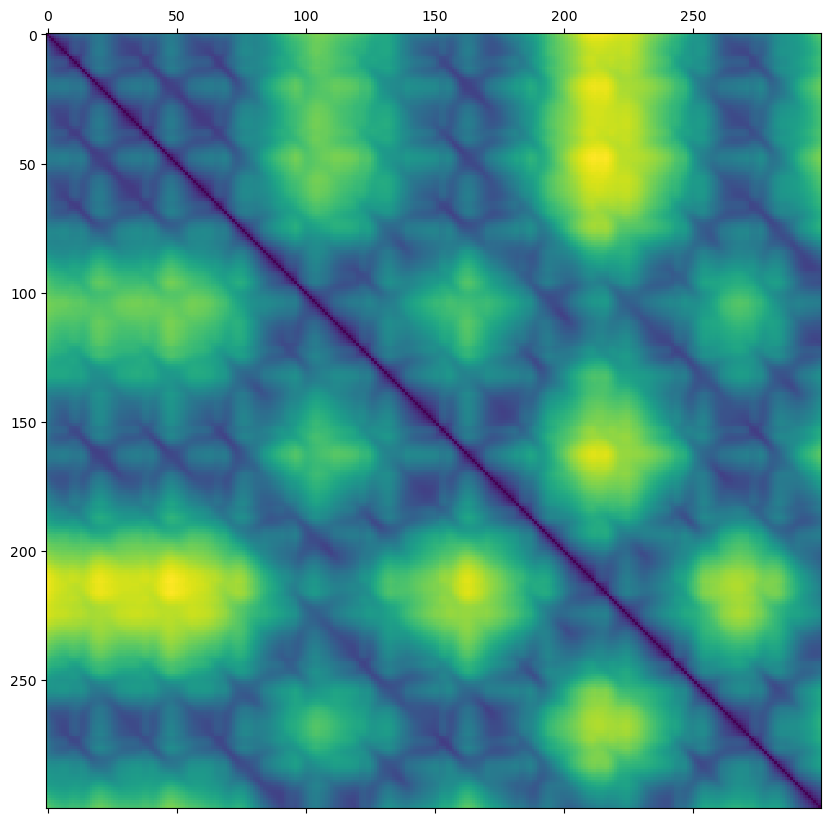

In [28]:
plt.matshow(D)

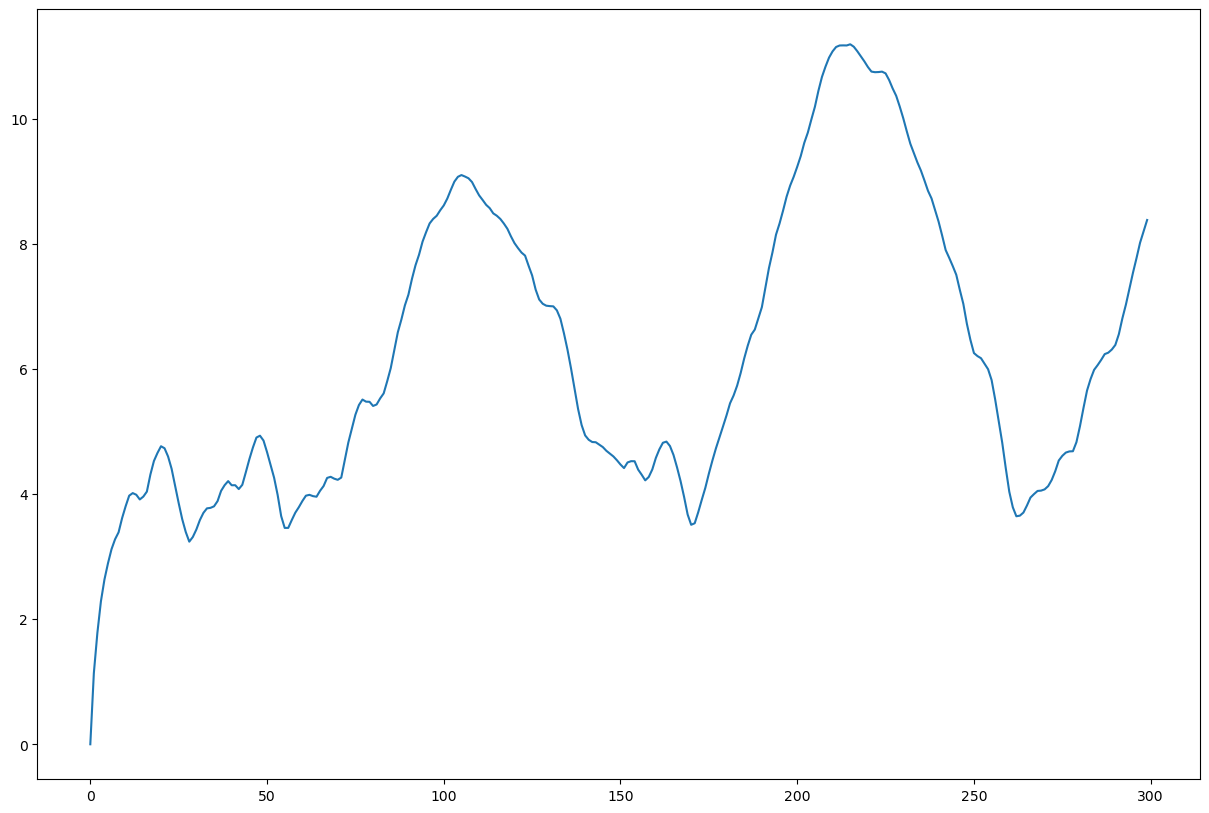

In [29]:
plt.plot(D[0,:])

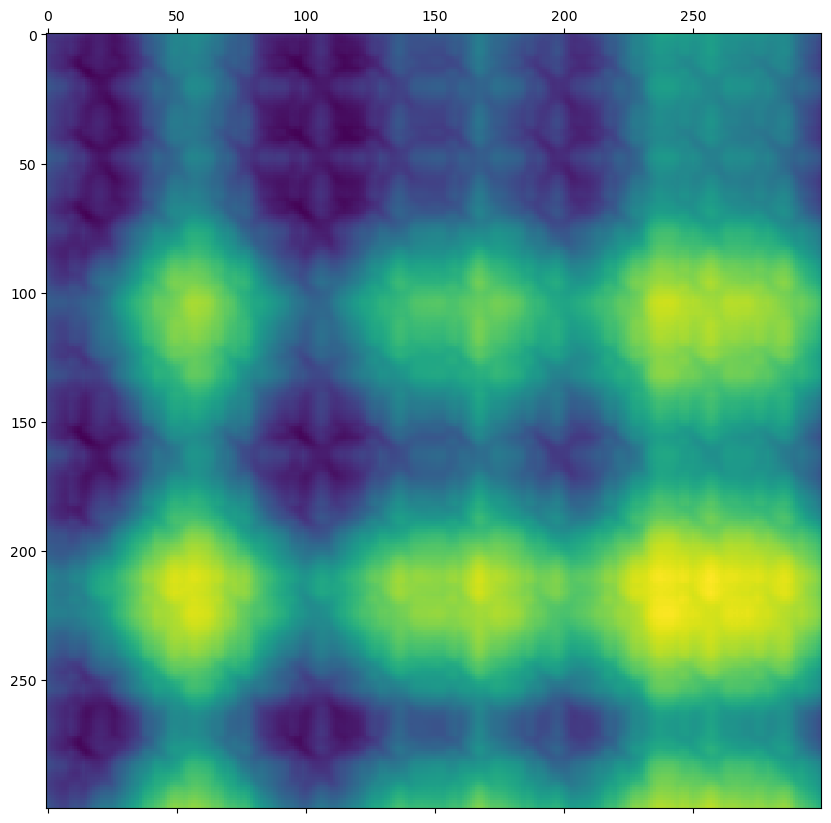

In [30]:
movie1 = X[0,1,:,:,:] / maxVal
time_x_img1 = movie1.reshape((300,200*200))
D1 = scipy.spatial.distance.cdist(time_x_img, time_x_img1)
plt.matshow(D1)

In [31]:
F = np.fft.rfft(time_x_img, axis=0)
F.shape

(151, 40000)

In [32]:
tim_x_img_tt10 = movie_tt10.T.reshape((300,200*200))
F_tt10 = np.fft.rfft(tim_x_img_tt10, axis=0)
tim_x_img_tt25 = movie_tt25.T.reshape((300,200*200))
F_tt25 = np.fft.rfft(tim_x_img_tt25, axis=0)

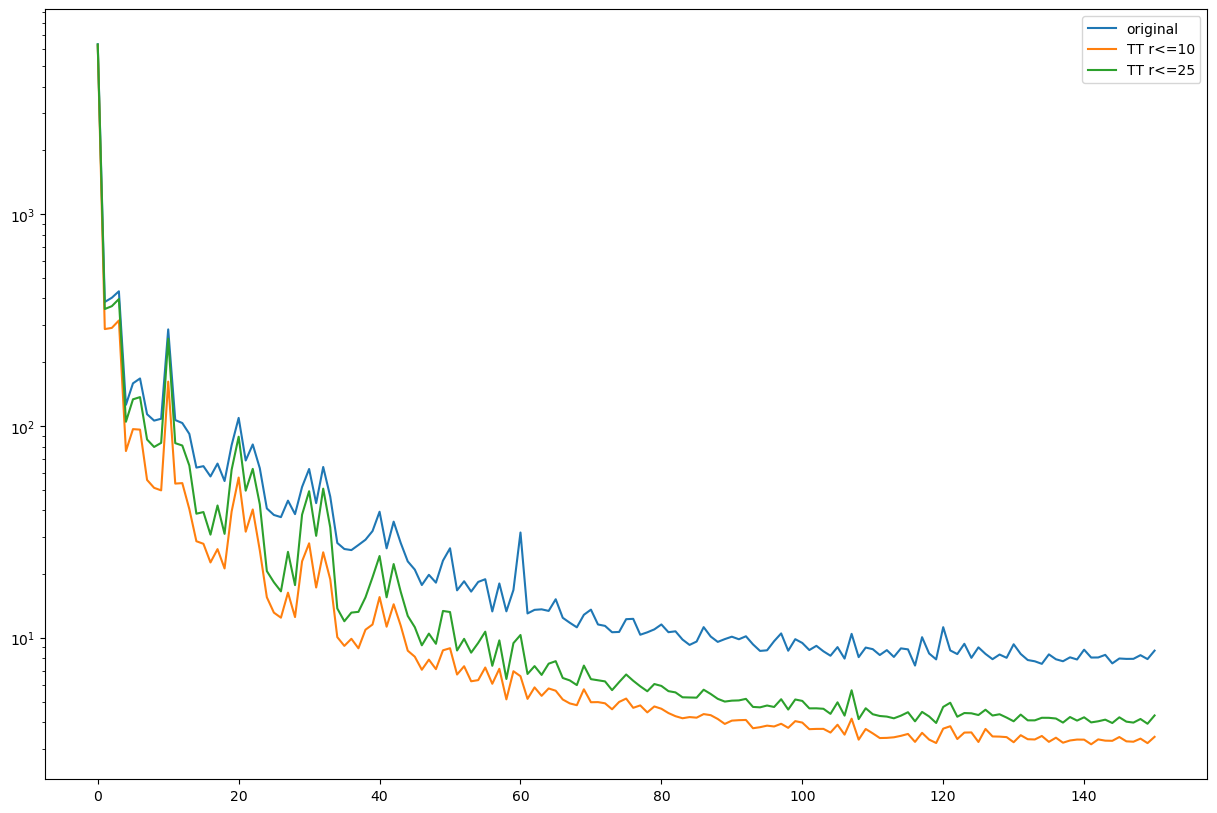

In [33]:
Fnrm = np.linalg.norm(F, axis=1)
Fnrm_tt10 = np.linalg.norm(F_tt10, axis=1)
Fnrm_tt25 = np.linalg.norm(F_tt25, axis=1)
plt.yscale('log')
plt.plot(Fnrm, label='original')
plt.plot(Fnrm_tt10, label='TT r<=10')
plt.plot(Fnrm_tt25, label='TT r<=25')
plt.legend()

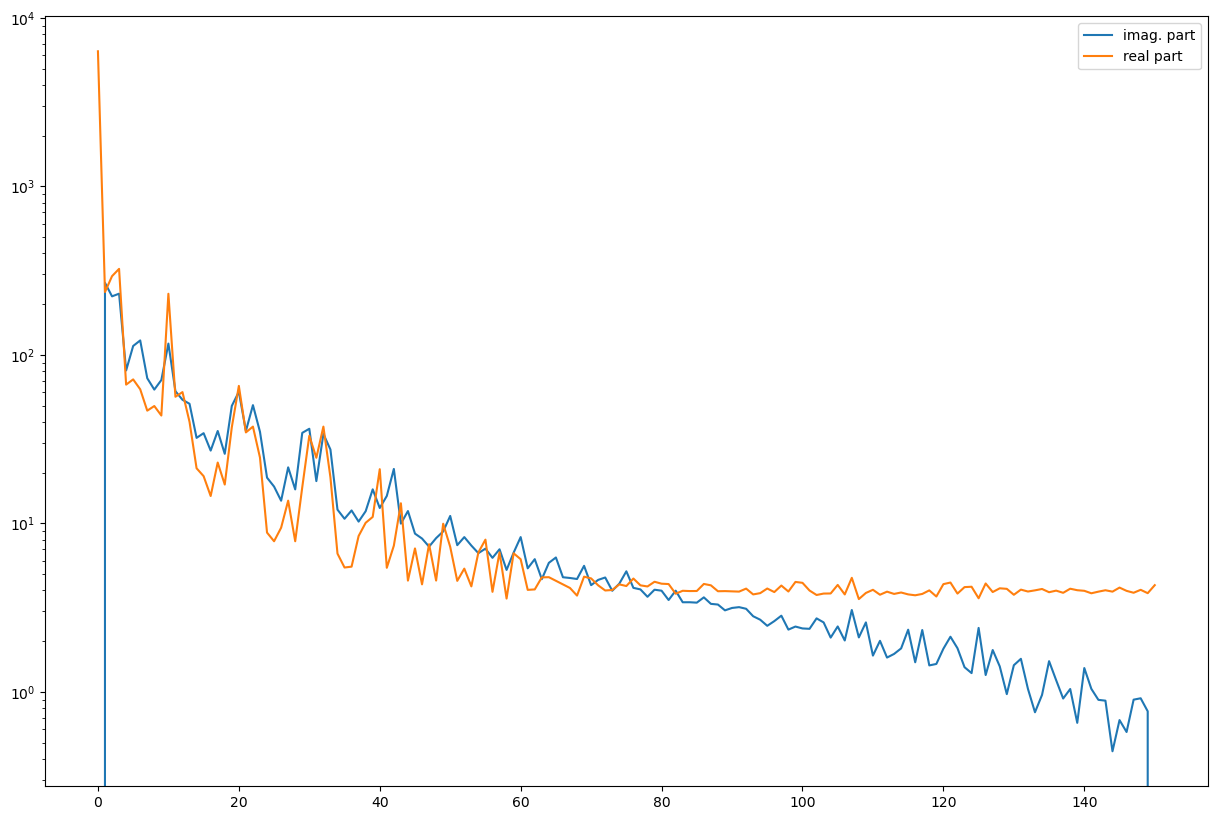

In [34]:
plt.yscale('log')
plt.plot(np.linalg.norm(np.imag(F_tt25), axis=1), label='imag. part')
plt.plot(np.linalg.norm(np.real(F_tt25), axis=1), label='real part')
plt.legend()

In [35]:
F_ = F
F_[20:,:] = 0
movie_lowpass = np.reshape(np.fft.irfft(F_, axis=0), (300,200,200))

In [36]:
display.Video(compareVideo('lowpass_example', (movie_lowpass, movie)))
# lowpass - original

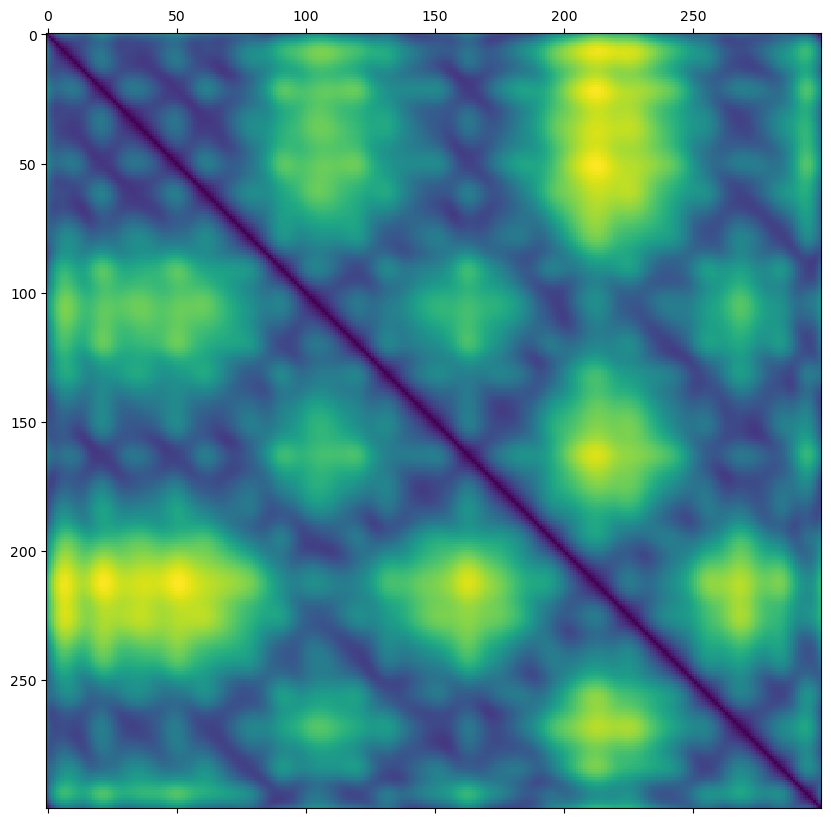

In [37]:
time_x_img_ = movie_lowpass.reshape((300,200*200))
D_ = scipy.spatial.distance.cdist(time_x_img_, time_x_img_)
plt.matshow(D_)

In [38]:
movie2 = X[0,2,:,:,:] / maxVal

In [39]:
D12 = np.zeros((30,30), dtype=np.float32)
for i in range(30):
    for j in range(30):
        D12[i,j] = np.linalg.norm(movie1[i:i+150,:,:,]-movie[j:j+150,:,:])

In [40]:
D23 = np.zeros((30,30), dtype=np.float32)
for i in range(30):
    for j in range(30):
        D23[i,j] = np.linalg.norm(movie2[20+i:20+i+150,:,:,]-movie1[20+j:20+j+150,:,:])

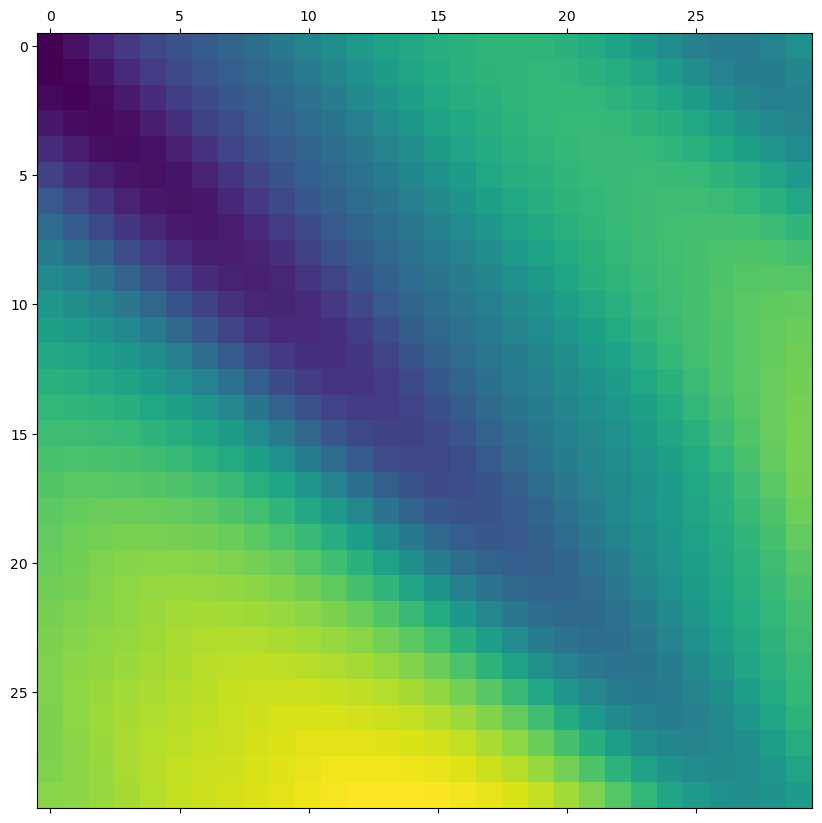

In [41]:
plt.matshow(D12)

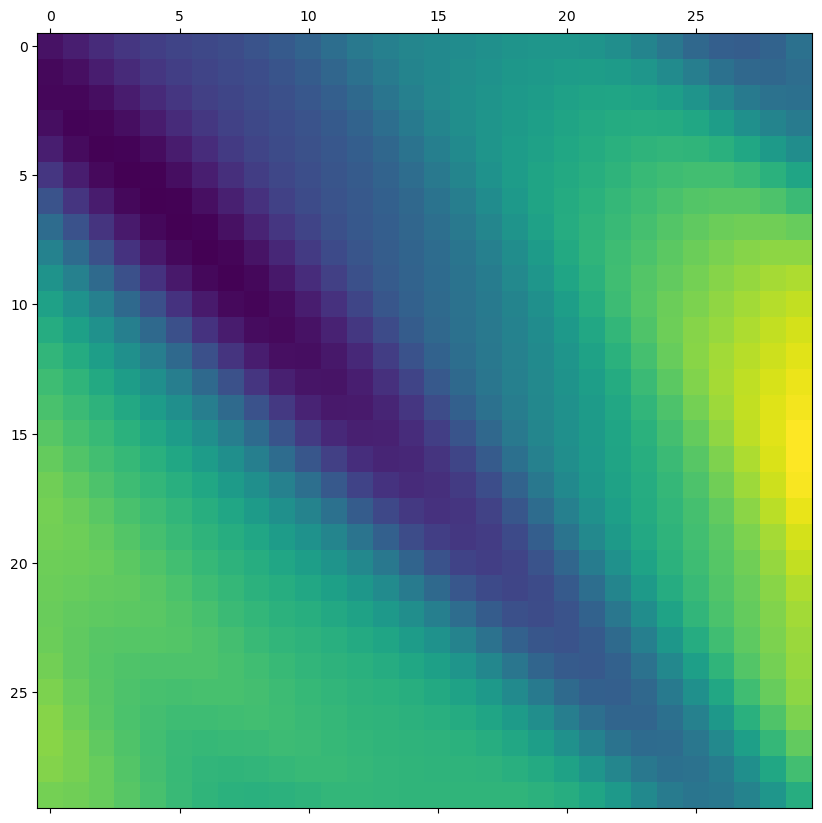

In [42]:
plt.matshow(D23)

In [43]:
display.Video(compareVideo('sliceVideos', (movie, movie1, movie2)))

In [44]:
time_x_img1 = movie1.reshape((300,200*200))
time_x_img2 = movie2.reshape((300,200*200))

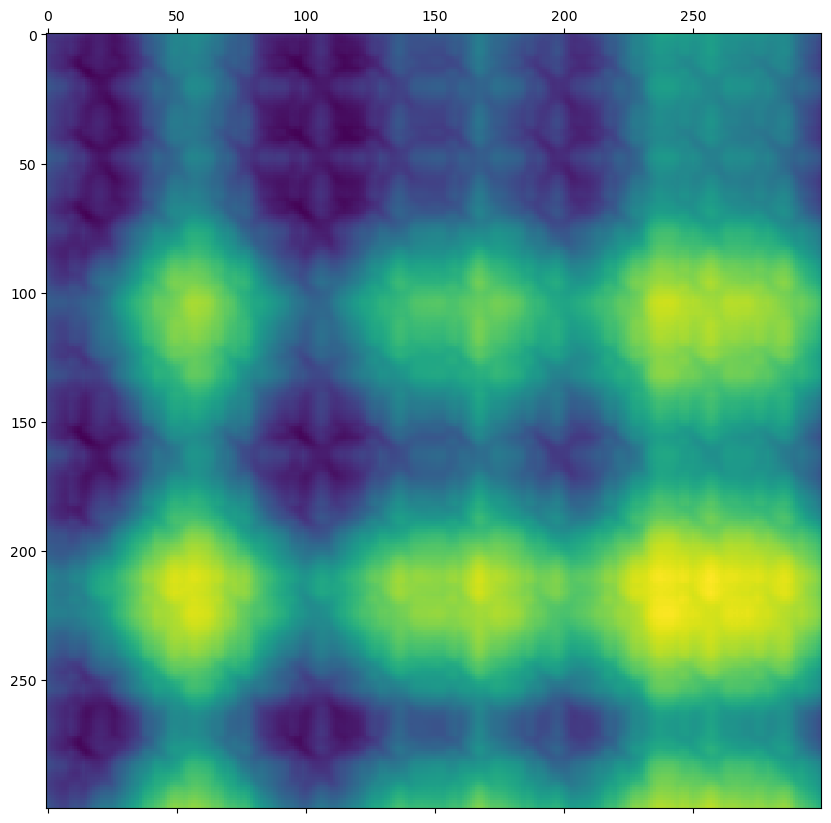

In [45]:
D01 = scipy.spatial.distance.cdist(time_x_img, time_x_img1)
plt.matshow(D01)

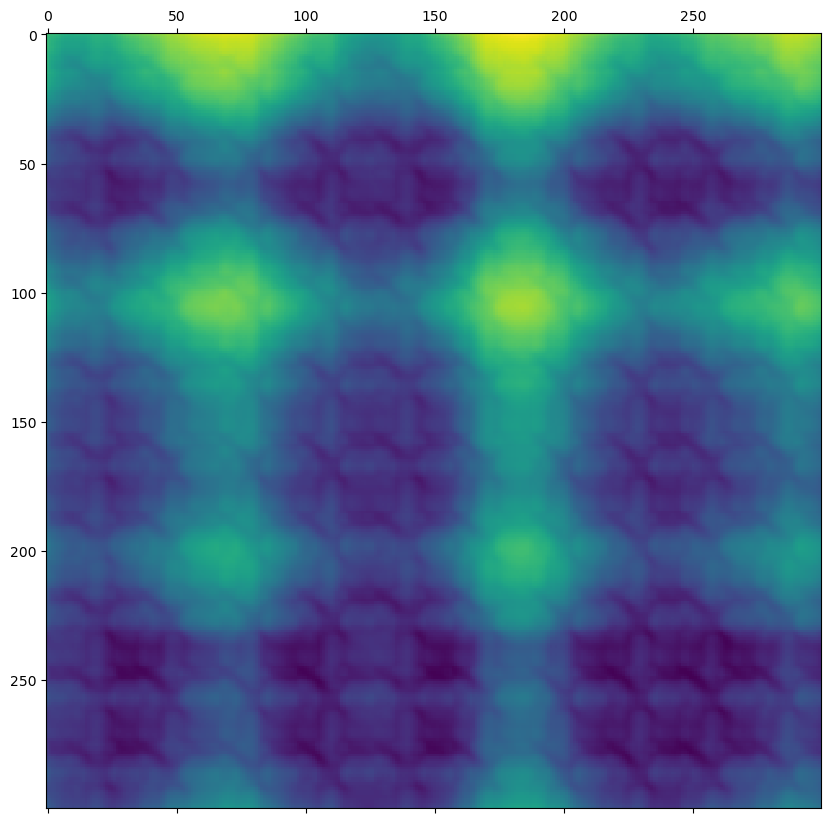

In [46]:
D12 = scipy.spatial.distance.cdist(time_x_img1, time_x_img2)
plt.matshow(D12)

In [47]:
D12_ = np.zeros((200,200), dtype=np.float32)
for i in range(200):
    for j in range(200):
        D12_[i,j] = np.linalg.norm(np.diag(D12[i:i+100,j:j+100]))

(np.int64(169), np.int64(199))

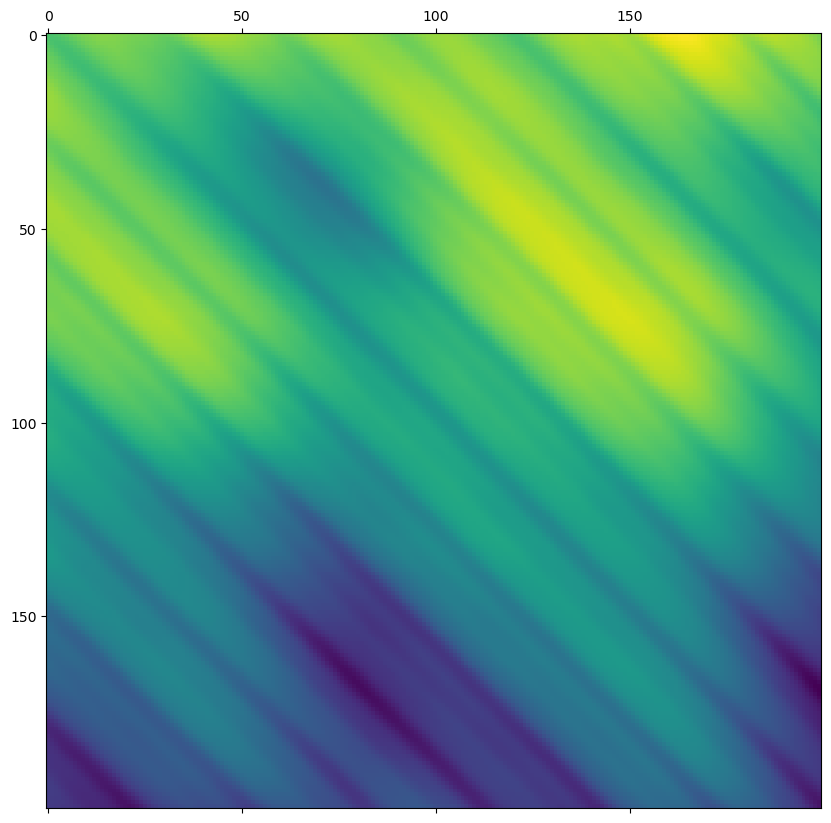

In [48]:
plt.matshow(D12_)
np.unravel_index(np.argmin(D12_), D12_.shape)

In [49]:
D12_[169,199]

np.float32(70.919586)

In [50]:
D01_ = np.zeros((200,200), dtype=np.float32)
for i in range(200):
    for j in range(200):
        D01_[i,j] = np.linalg.norm(np.diag(D01[i:i+100,j:j+100]))

(np.int64(0), np.int64(28))

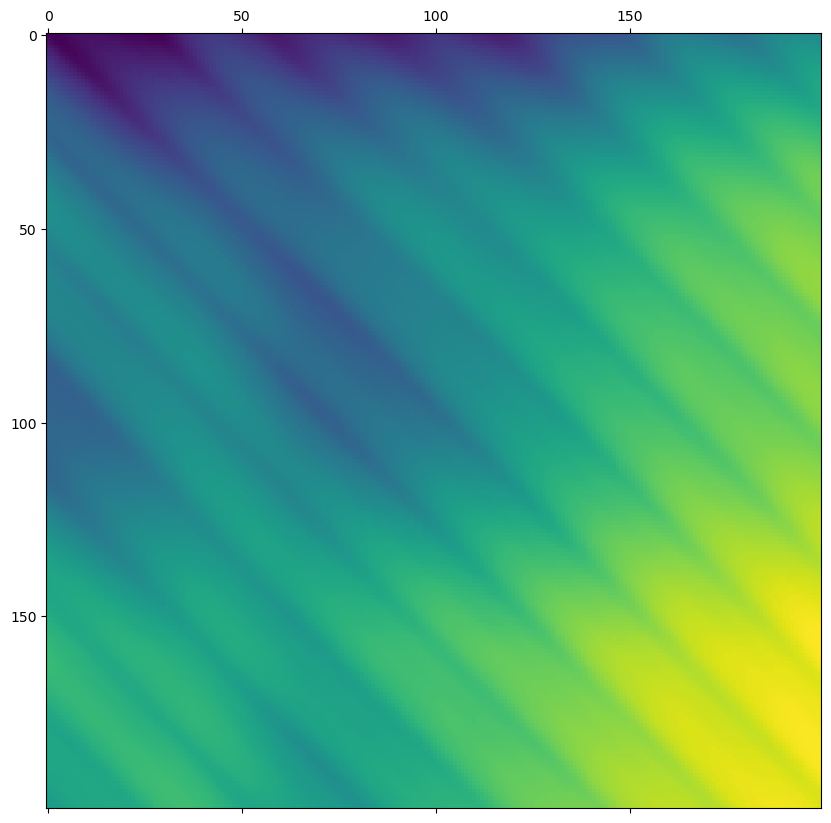

In [51]:
plt.matshow(D01_)
np.unravel_index(np.argmin(D01_), D01_.shape)

In [52]:
D123 = np.zeros((200,200,200), dtype=np.float32)
for i in range(200):
    for j in range(200):
        for k in range(200):
            D123[i,j,k] = np.sqrt(D01_[i,j]**2 + D12_[j,k]**2)

In [53]:
np.unravel_index(np.argmin(D123), D123.shape)

(np.int64(0), np.int64(29), np.int64(61))

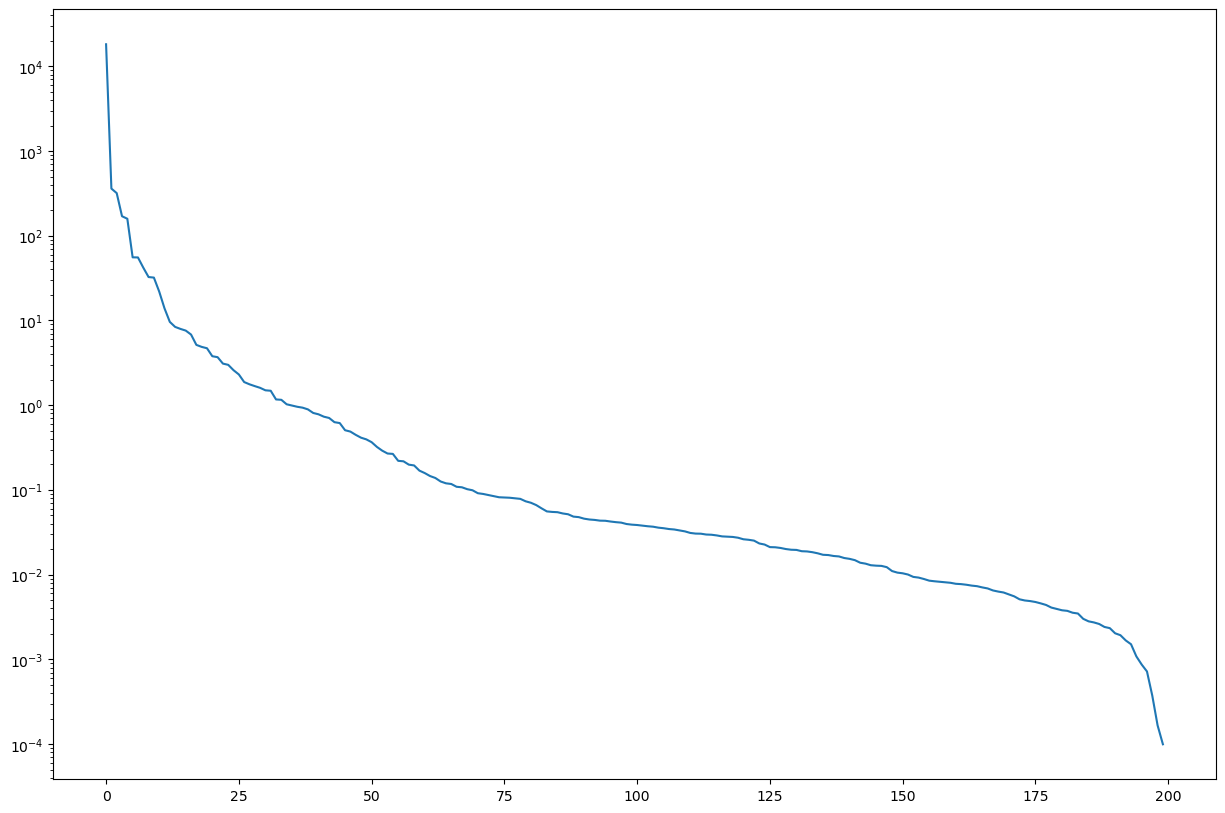

In [54]:
U, S, Vt = np.linalg.svd(D12_)
plt.yscale('log')
plt.plot(S)

In [55]:
movie = X[0,0,:,:,:] / maxVal
movie1 = X[0,1,:,:,:] / maxVal
movie2 = X[0,2,:,:,:] / maxVal
display.Video(compareVideo('sliceVideos', (movie[0:0+100,:,:], movie1[29:29+100,:,:], movie2[61:61+100,:,:])))

In [56]:
movie_ = X[2,0,:,:,:] / maxVal
movie1_ = X[2,1,:,:,:] / maxVal
movie2_ = X[2,2,:,:,:] / maxVal
display.Video(compareVideo('sliceVideos_unsync3', (movie_[200:300,:,:], movie1_[200:300,:,:], movie2_[200:300,:,:])))

In [57]:
movie3 = X[0,3,:,:,:] / maxVal

In [58]:
display.Video(compareVideo('sliceVideos23', (movie2, movie3)))

In [59]:
# read compressed data

tt_dict = np.load('Xtt0.npz', allow_pickle=True)
Xtt = dict_to_tensortrain(tt_dict)

FileNotFoundError: [Errno 2] No such file or directory: 'Xtt0.npz'

In [ ]:
print(Xtt)

In [ ]:
size = 0
for iDim in range(len(Xtt.dimensions())):
    size = size + Xtt.getSubTensor(iDim).size
size

In [ ]:
# in MB
size*4 / 10**6

In [ ]:
X.size

In [ ]:
# in MB
X.size*4 / 10**6

In [ ]:
# uint16 in MB
X.size*2 / 10**6